# HUMAN ACTIVITY RECOGNITION USING MACHINE LEARNING

### A Comparative Study of Supervised and Unsupervised Learning Algorithms

**Dataset:** UCI Human Activity Recognition Using Smartphones

## 1. Introduction

Human Activity Recognition (HAR) is the process of identifying human activities using sensor data collected from smartphones or wearable devices.

This project focuses on recognizing six human activities using machine learning techniques. The dataset contains sensor measurements collected from smartphones worn by 30 volunteers performing different physical activities.

The project explores both supervised and unsupervised machine learning approaches.

### 2. Project Objectives

1. Understand and explore the Human Activity Recognition dataset.
2. Perform Exploratory Data Analysis (EDA).
3. Prepare and preprocess the dataset.
4. Implement K-Nearest Neighbors (KNN) classification.
5. Implement Decision Tree classification.
6. Implement Random Forest classification.
7. Compare the performance of supervised learning algorithms.
8. Apply K-Means clustering to identify patterns in the dataset.
9. Evaluate clustering performance using Silhouette Score, ARI and NMI.
10. Analyze and compare the results.

### 3. Algorithms Used

**Supervised Learning:**
- K-Nearest Neighbors (KNN)
- Decision Tree
- Random Forest

**Unsupervised Learning:**
- K-Means Clustering

### 4. Project Team Contributions

- Member 1: Data Collection, Understanding and Exploratory Data Analysis.
- Member 2: KNN and Decision Tree Classification.
- Member 3: Random Forest Classification and Data Preprocessing.
- Member 4: K-Means Clustering, Evaluation and Final Integration.

## 2. Dataset Description

This project uses the **UCI Human Activity Recognition Using Smartphones Dataset**.

The dataset was collected from 30 volunteers performing six different physical activities while carrying a waist-mounted smartphone equipped with embedded inertial sensors.

### Dataset Information

- Total observations: 10,299
- Number of features: 561
- Number of activity classes: 6
- Number of volunteers: 30
- Training observations: 7,352
- Testing observations: 2,947

### Activity Classes

| Label | Activity |
|---|---|
| 1 | WALKING |
| 2 | WALKING_UPSTAIRS |
| 3 | WALKING_DOWNSTAIRS |
| 4 | SITTING |
| 5 | STANDING |
| 6 | LAYING |

### Dataset Features

The dataset contains numerical features extracted from smartphone accelerometer and gyroscope signals.

These features represent different movement patterns and are used by machine learning algorithms to recognize human activities.

### Dataset Structure

The original dataset is divided into two subsets:

- Training dataset: Used to train the supervised learning models.
- Testing dataset: Used to evaluate model performance on unseen observations.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np
import os

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning algorithms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Dimensionality reduction
from sklearn.decomposition import PCA

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Set the dataset path
DATASET_PATH = "../UCI HAR Dataset"

# Load feature names
features = pd.read_csv(
    os.path.join(DATASET_PATH, "features.txt"),
    sep=r"\s+",
    header=None,
    usecols=[1]
)[1].tolist()

# Make duplicate feature names unique
unique_features = []
counts = {}

for name in features:
    if name not in counts:
        counts[name] = 0
        unique_features.append(name)
    else:
        counts[name] += 1
        unique_features.append(f"{name}_{counts[name]}")

# Load activity labels
activity_labels = pd.read_csv(
    os.path.join(DATASET_PATH, "activity_labels.txt"),
    sep=r"\s+",
    header=None,
    names=["Activity_ID", "Activity"]
)

# Load training data
X_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train", "X_train.txt"),
    sep=r"\s+",
    header=None
)

X_train.columns = unique_features

y_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train", "y_train.txt"),
    header=None,
    names=["Activity"]
)["Activity"]

# Load testing data
X_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test", "X_test.txt"),
    sep=r"\s+",
    header=None
)

X_test.columns = unique_features

y_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test", "y_test.txt"),
    header=None,
    names=["Activity"]
)["Activity"]

print("Dataset loaded successfully!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training features: (7352, 561)
Testing features: (2947, 561)
Training labels: (7352,)
Testing labels: (2947,)


In [3]:
# Combine training and testing data for overall inspection
X = pd.concat([X_train, X_test], ignore_index=True)
y = pd.concat([y_train, y_test], ignore_index=True)

# Dataset dimensions
print("Total observations:", X.shape[0])
print("Total features:", X.shape[1])

# Check missing values
print("\nMissing values:", X.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", X.duplicated().sum())

# Activity distribution
activity_counts = y.value_counts().sort_index()

activity_distribution = pd.DataFrame({
    "Activity_ID": activity_counts.index,
    "Count": activity_counts.values
})

activity_distribution = activity_distribution.merge(
    activity_labels,
    on="Activity_ID"
)

print("\nActivity Distribution:")
display(activity_distribution)

Total observations: 10299
Total features: 561

Missing values: 0
Duplicate rows: 0

Activity Distribution:


,Activity_ID,Count,Activity
0,1,1722,WALKING
1,2,1544,WALKING_UPSTAIRS
2,3,1406,WALKING_DOWNSTAIRS
3,4,1777,SITTING
4,5,1906,STANDING
5,6,1944,LAYING


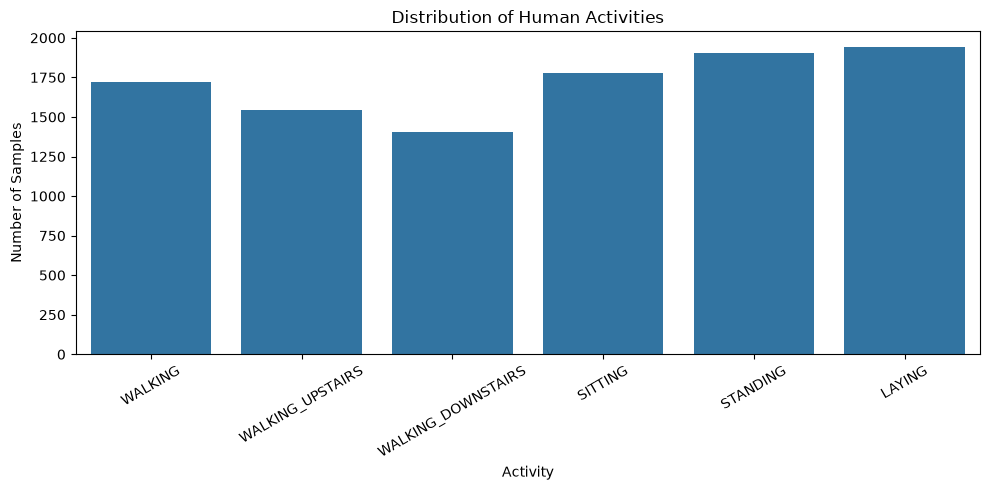

In [4]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=activity_distribution,
    x="Activity",
    y="Count"
)

plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [5]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data shape: (7352, 561)
Scaled testing data shape: (2947, 561)


In [6]:
# Initialize KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Make predictions
knn_predictions = knn_model.predict(X_test_scaled)

# Evaluate accuracy
knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Model Training Completed!")
print("KNN Accuracy:", round(knn_accuracy, 4))

KNN Model Training Completed!
KNN Accuracy: 0.8802


In [7]:
# Calculate KNN evaluation metrics
knn_precision = precision_score(y_test, knn_predictions, average="weighted")
knn_recall = recall_score(y_test, knn_predictions, average="weighted")
knn_f1 = f1_score(y_test, knn_predictions, average="weighted")

print("KNN Classification Report")
print("-------------------------")
print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))

KNN Classification Report
-------------------------
Accuracy : 0.8802
Precision: 0.8883
Recall   : 0.8802
F1 Score : 0.879


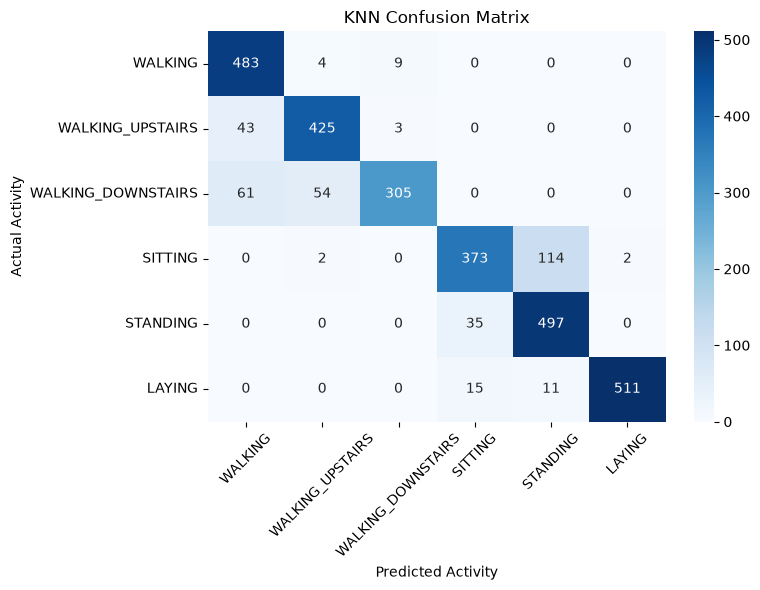

In [8]:
# Generate confusion matrix
knn_cm = confusion_matrix(y_test, knn_predictions)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_labels["Activity"],
    yticklabels=activity_labels["Activity"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Initialize Decision Tree classifier
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Model Training Completed!")
print("Decision Tree Accuracy:", round(dt_accuracy, 4))

Decision Tree Model Training Completed!
Decision Tree Accuracy: 0.8622


In [10]:
# Calculate Decision Tree evaluation metrics
dt_precision = precision_score(y_test, dt_predictions, average="weighted")
dt_recall = recall_score(y_test, dt_predictions, average="weighted")
dt_f1 = f1_score(y_test, dt_predictions, average="weighted")

print("Decision Tree Classification Report")
print("-----------------------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))

Decision Tree Classification Report
-----------------------------------
Accuracy : 0.8622
Precision: 0.8633
Recall   : 0.8622
F1 Score : 0.8617


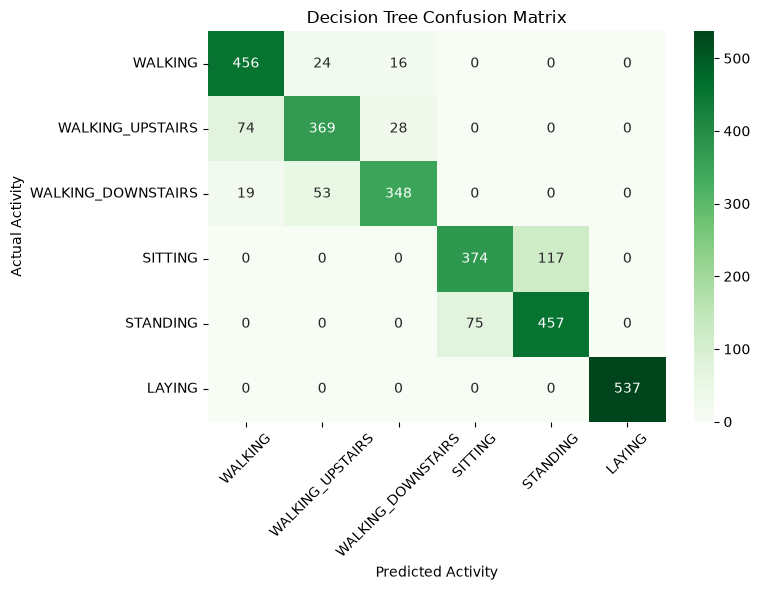

In [11]:
# Generate confusion matrix
dt_cm = confusion_matrix(y_test, dt_predictions)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=activity_labels["Activity"],
    yticklabels=activity_labels["Activity"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Initialize Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Model Training Completed!")
print("Random Forest Accuracy:", round(rf_accuracy, 4))

Random Forest Model Training Completed!
Random Forest Accuracy: 0.9257


In [13]:
# Calculate Random Forest evaluation metrics
rf_precision = precision_score(y_test, rf_predictions, average="weighted")
rf_recall = recall_score(y_test, rf_predictions, average="weighted")
rf_f1 = f1_score(y_test, rf_predictions, average="weighted")

print("Random Forest Classification Report")
print("-----------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))

Random Forest Classification Report
-----------------------------------
Accuracy : 0.9257
Precision: 0.927
Recall   : 0.9257
F1 Score : 0.9255


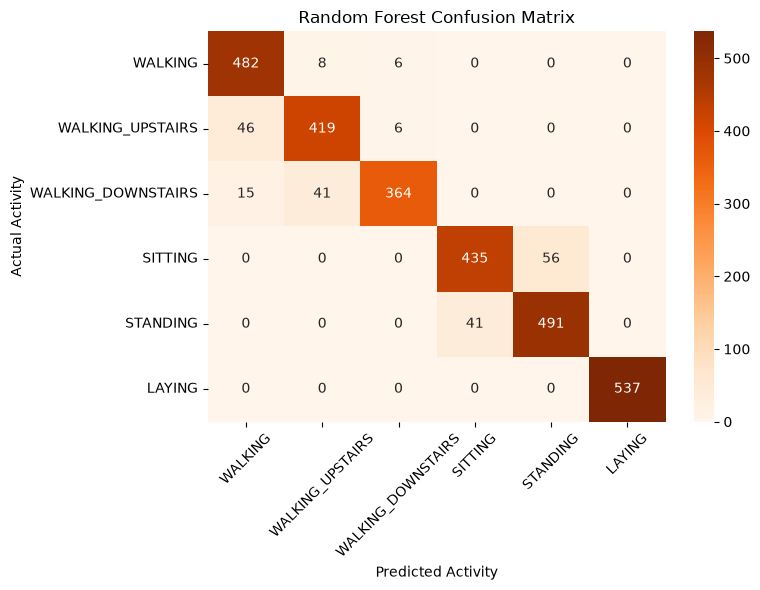

In [14]:
# Generate confusion matrix
rf_cm = confusion_matrix(y_test, rf_predictions)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=activity_labels["Activity"],
    yticklabels=activity_labels["Activity"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
# Create a comparison DataFrame
model_comparison = pd.DataFrame({
    "Model": ["KNN", "Decision Tree", "Random Forest"],
    "Accuracy": [knn_accuracy, dt_accuracy, rf_accuracy],
    "Precision": [knn_precision, dt_precision, rf_precision],
    "Recall": [knn_recall, dt_recall, rf_recall],
    "F1 Score": [knn_f1, dt_f1, rf_f1]
})

print("Classification Model Performance Comparison")
display(model_comparison.round(4))

Classification Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8802,0.8883,0.8802,0.8790
1,Decision Tree,0.8622,0.8633,0.8622,0.8617
2,Random Forest,0.9257,0.9270,0.9257,0.9255


<Figure size 1000x600 with 0 Axes>

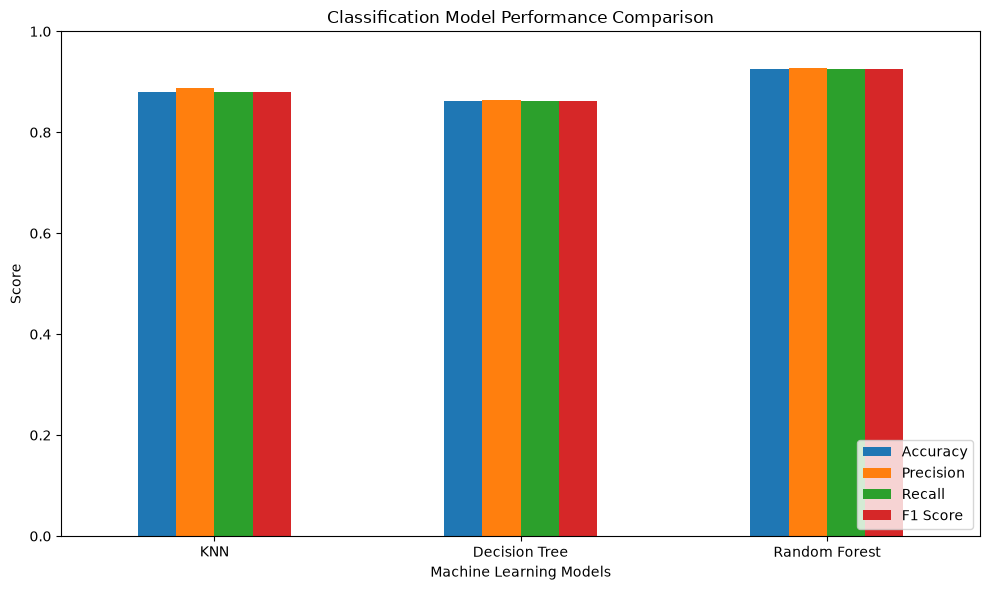

In [16]:
plt.figure(figsize=(10, 6))

model_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [17]:
# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": unique_features,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
print("Top 10 Most Important Features:")
display(feature_importance.head(10))

Top 10 Most Important Features:


,Feature,Importance
40,tGravityAcc-mean()-X,0.036380
49,tGravityAcc-max()-X,0.030331
558,"angle(X,gravityMean)",0.029676
41,tGravityAcc-mean()-Y,0.025355
56,tGravityAcc-energy()-X,0.024963
559,"angle(Y,gravityMean)",0.024415
52,tGravityAcc-min()-X,0.022650
50,tGravityAcc-max()-Y,0.021705
53,tGravityAcc-min()-Y,0.021635
57,tGravityAcc-energy()-Y,0.017179


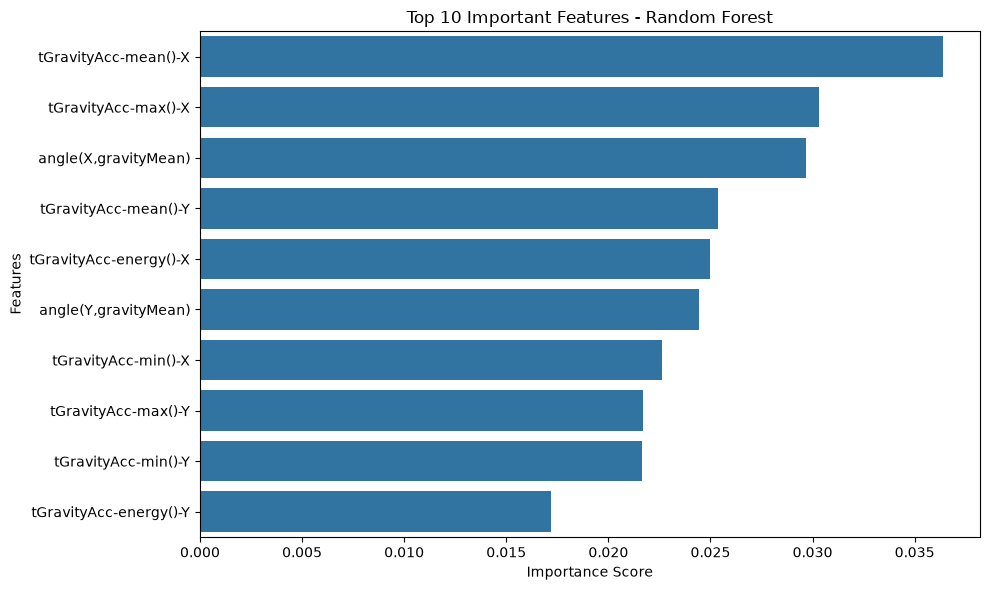

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [19]:
# Combine scaled training and testing features
X_cluster = np.concatenate(
    [X_train_scaled, X_test_scaled],
    axis=0
)

# Combine actual activity labels for later evaluation
y_actual = pd.concat(
    [y_train, y_test],
    ignore_index=True
)

print("Clustering data prepared successfully!")
print("Clustering features shape:", X_cluster.shape)
print("Actual labels shape:", y_actual.shape)

Clustering data prepared successfully!
Clustering features shape: (10299, 561)
Actual labels shape: (10299,)


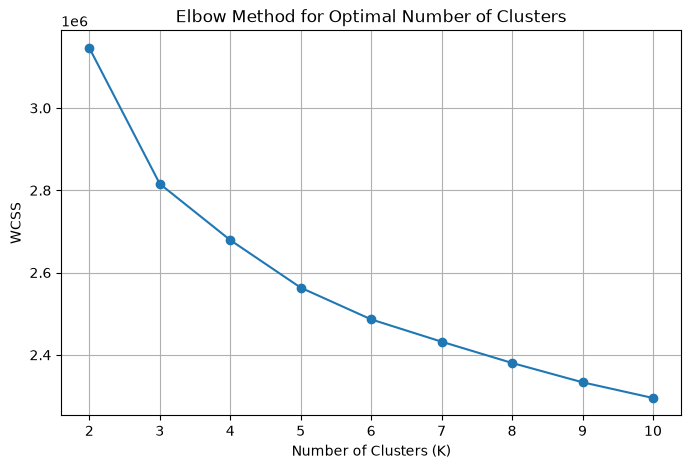

In [20]:
# Calculate WCSS for different numbers of clusters
wcss = []

for i in range(2, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [21]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster,
        cluster_labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3936
K = 3, Silhouette Score = 0.3089
K = 4, Silhouette Score = 0.1487
K = 5, Silhouette Score = 0.1293
K = 6, Silhouette Score = 0.1078
K = 7, Silhouette Score = 0.0807
K = 8, Silhouette Score = 0.0756
K = 9, Silhouette Score = 0.0730
K = 10, Silhouette Score = 0.0739


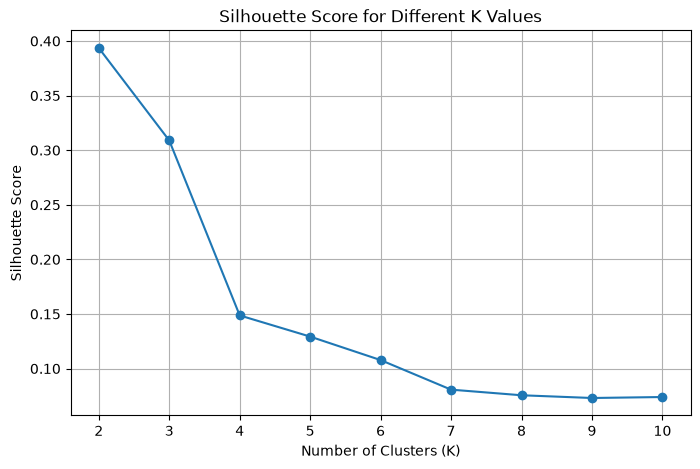

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [23]:
ari_scores = []
nmi_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    ari = adjusted_rand_score(y_actual, cluster_labels)
    nmi = normalized_mutual_info_score(y_actual, cluster_labels)

    ari_scores.append(ari)
    nmi_scores.append(nmi)

    print(
        f"K = {k} | ARI = {ari:.4f} | NMI = {nmi:.4f}"
    )

K = 2 | ARI = 0.3297 | NMI = 0.5459
K = 3 | ARI = 0.3324 | NMI = 0.5192
K = 4 | ARI = 0.2991 | NMI = 0.4692
K = 5 | ARI = 0.2916 | NMI = 0.4607
K = 6 | ARI = 0.4184 | NMI = 0.5587
K = 7 | ARI = 0.4367 | NMI = 0.5571
K = 8 | ARI = 0.4351 | NMI = 0.5578
K = 9 | ARI = 0.4382 | NMI = 0.5539
K = 10 | ARI = 0.4416 | NMI = 0.5616


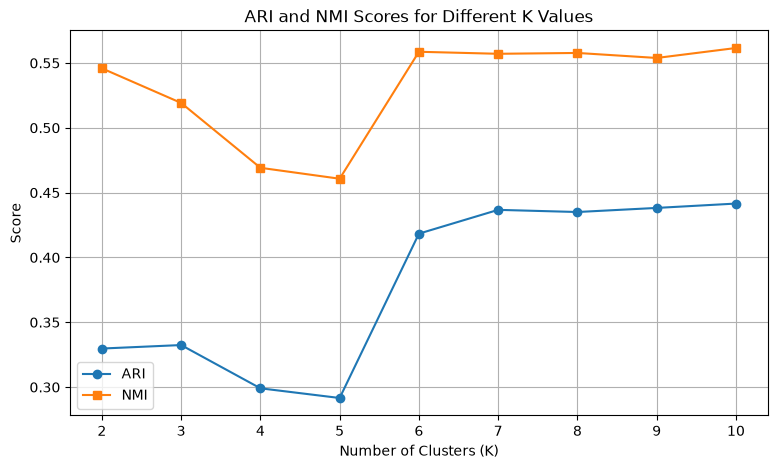

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    ari_scores,
    marker='o',
    label='ARI'
)

plt.plot(
    range(2, 11),
    nmi_scores,
    marker='s',
    label='NMI'
)

plt.title("ARI and NMI Scores for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Score")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Reduce 561 features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

# Calculate explained variance
explained_variance = sum(pca.explained_variance_ratio_) * 100

print("PCA completed successfully!")
print("Reduced data shape:", X_pca.shape)
print(f"Explained variance: {explained_variance:.2f}%")

PCA completed successfully!
Reduced data shape: (10299, 2)
Explained variance: 56.73%


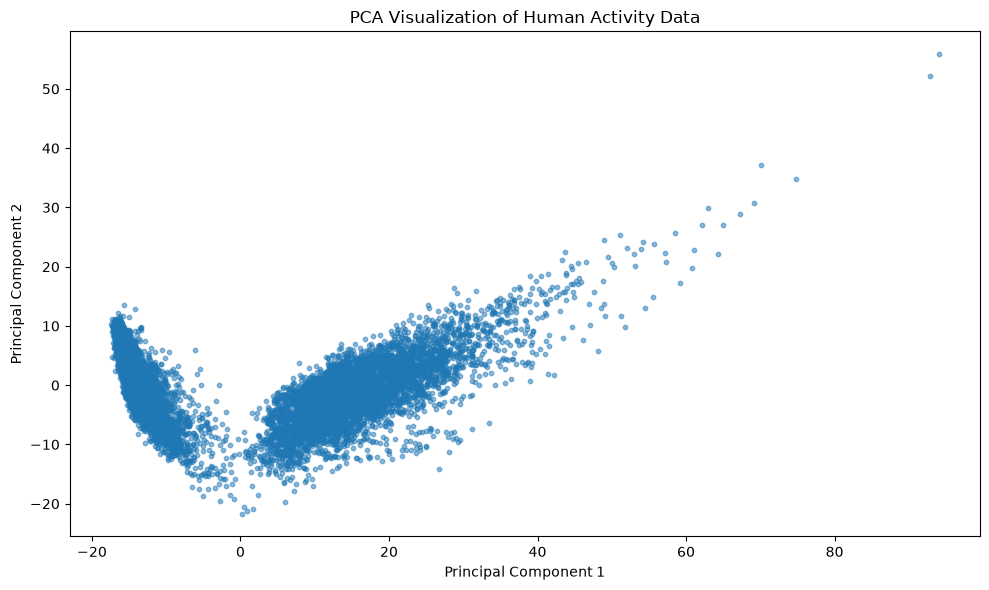

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.5,
    s=10
)

plt.title("PCA Visualization of Human Activity Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [27]:
# Train final K-Means model
final_kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

# Fit model using features only
final_clusters = final_kmeans.fit_predict(X_cluster)

print("Final K-Means model trained successfully!")
print("Number of clusters:", len(np.unique(final_clusters)))

Final K-Means model trained successfully!
Number of clusters: 10


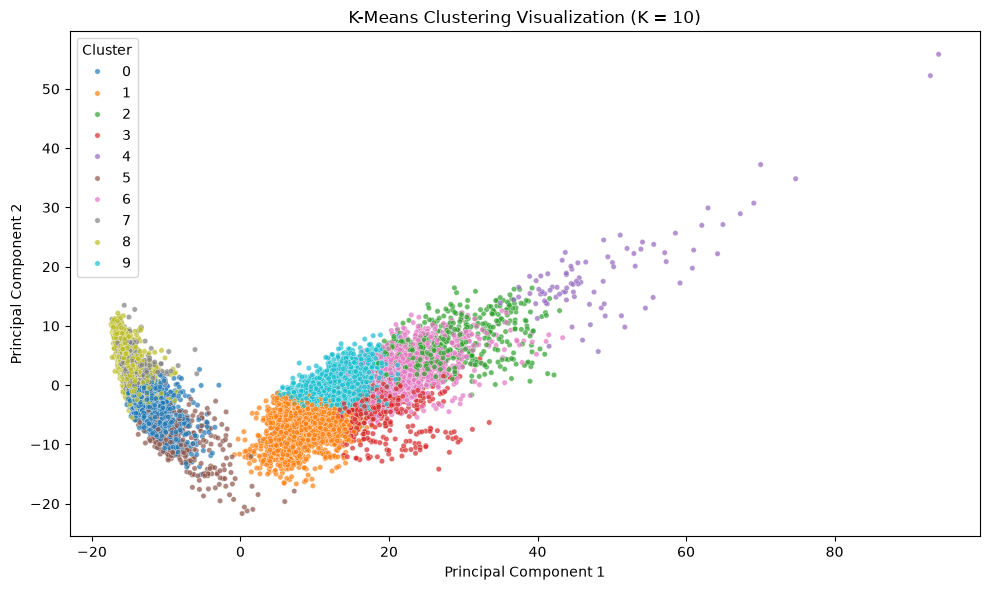

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=final_clusters,
    palette="tab10",
    s=15,
    alpha=0.7,
    legend="full"
)

plt.title("K-Means Clustering Visualization (K = 10)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [29]:
# Create a comparison table
cluster_comparison = pd.crosstab(
    final_clusters,
    y_actual
)

# Add meaningful activity names
cluster_comparison.columns = [
    activity_labels.set_index("Activity_ID").loc[col, "Activity"]
    for col in cluster_comparison.columns
]

print("Cluster vs Actual Activity Comparison:")
display(cluster_comparison)

Cluster vs Actual Activity Comparison:


,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
row_0,,,,,,
0,0,0,0,572,946,111
1,251,1018,185,1,0,2
2,211,21,195,0,0,0
3,81,301,18,0,0,0
4,9,0,76,0,0,0
5,0,0,0,106,35,195
6,198,78,689,0,0,0
7,0,0,0,1030,925,47
8,0,0,0,68,0,1589


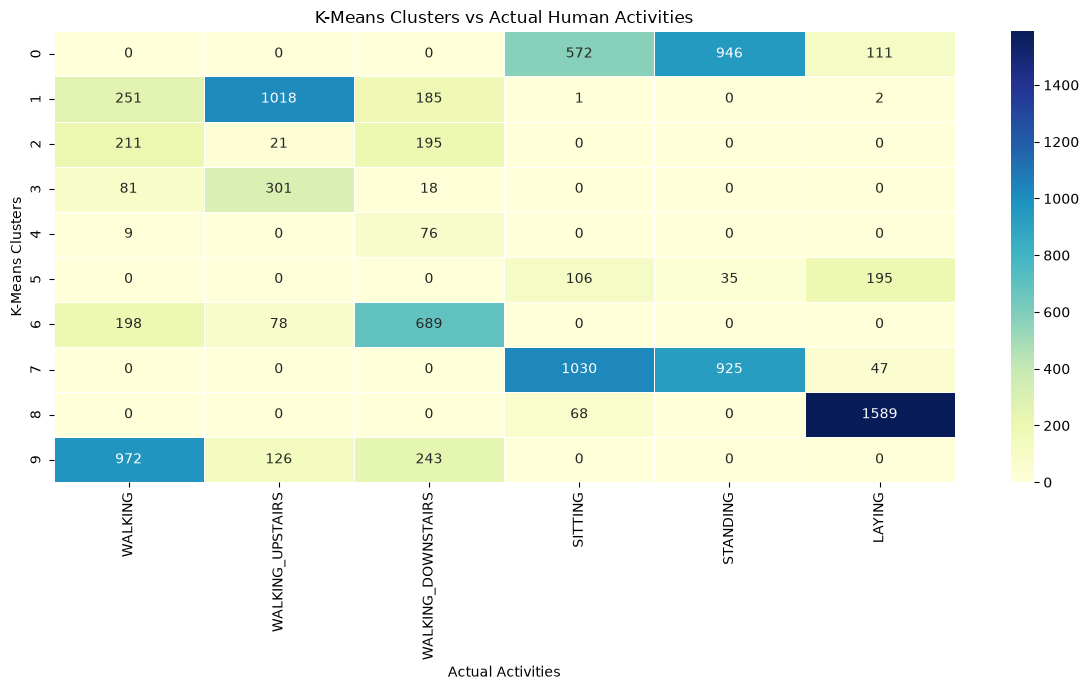

In [30]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    cluster_comparison,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("K-Means Clusters vs Actual Human Activities")
plt.xlabel("Actual Activities")
plt.ylabel("K-Means Clusters")

plt.tight_layout()
plt.show()

### K-Means Clustering – Results and Interpretation

K-Means clustering was applied to the scaled Human Activity Recognition dataset using 10 clusters. The Elbow Method, Silhouette Score, Adjusted Rand Index (ARI), and Normalized Mutual Information (NMI) were used to evaluate clustering performance.

The evaluation showed that K = 10 achieved the highest ARI (0.4416) and NMI (0.5616) among the tested values from 2 to 10. However, the Elbow Method suggested a bend around K = 4, indicating that the choice of cluster number involves a trade-off between different evaluation criteria.

The cluster comparison heatmap revealed the following patterns:

- Cluster 8 was predominantly associated with LAYING.
- Cluster 1 was predominantly associated with WALKING_UPSTAIRS.
- Cluster 6 was predominantly associated with WALKING_DOWNSTAIRS.
- Cluster 9 was predominantly associated with WALKING.
- Clusters 0 and 7 contained substantial SITTING and STANDING observations.

Some activities were distributed across multiple clusters, indicating that K-Means did not perfectly reproduce the original six activity classes.

Overall, K-Means identified meaningful patterns in the sensor data and demonstrated the usefulness of unsupervised learning for human activity recognition.

The Silhouette Score was highest for K = 2 (0.3936) and gradually decreased as the number of clusters increased. This suggests that fewer clusters provided better separation and compactness. Therefore, selecting K = 10 based on ARI and NMI involves a trade-off, as it provides better agreement with the actual activity labels among the tested values but has a lower Silhouette Score.

# Overall Project Conclusion

The project **Human Activity Recognition Using Machine Learning** aimed to identify six different human activities using smartphone sensor data.

The dataset contained 10,299 observations and 561 numerical features representing sensor measurements collected from 30 volunteers.

The project involved data collection, exploratory data analysis, preprocessing, supervised machine learning, and unsupervised machine learning.

Three supervised classification algorithms were implemented and evaluated:

- **K-Nearest Neighbors (KNN):** Achieved an accuracy of approximately 88.02%.
- **Decision Tree:** Achieved an accuracy of approximately 86.22%.
- **Random Forest:** Achieved an accuracy of approximately 92.57%.

Among these models, Random Forest achieved the highest classification accuracy and performed better than KNN and Decision Tree on the evaluated metrics.

K-Means clustering was also applied to identify patterns in the sensor data without using activity labels during training. PCA was used to reduce the feature dimensions for visualization. The clustering results showed that several activities formed meaningful groups, although some activities overlapped or were distributed across multiple clusters.

The final K-Means model used 10 clusters and achieved an Adjusted Rand Index (ARI) of 0.4416 and a Normalized Mutual Information (NMI) score of 0.5616. The Silhouette Score for K = 10 was 0.0739, indicating relatively weak cluster separation. These results highlight the trade-off between agreement with actual activity labels and cluster separation.

The results demonstrate that machine learning techniques can effectively recognize human activities using smartphone sensor data. The project also provided practical experience with data preprocessing, exploratory data analysis, classification algorithms, clustering, dimensionality reduction, and model evaluation.

**Overall, Random Forest was the best-performing supervised classification model in this project, while K-Means provided useful insights into the underlying structure of the activity data.**